# 01. Загрузка и первичный осмотр данных

## Цель
Проверить корректность загрузки исходных данных, изучить структуру таблицы и выявить вопросы, которые необходимо решить на этапе очистки.

*В этом ноутбуке не выполняются очистка данных, формирование целевых классов, создание признаков и обучение моделей.*


## Импорт библиотек

In [1]:
import pandas as pd 

## Загрузка tsv файла и первичный осмотр структуры данных

Исходные данные взяты с база данных UniProtKB, раздел Swiss-Prot; объект — белки человека и скачан в формате TSV.

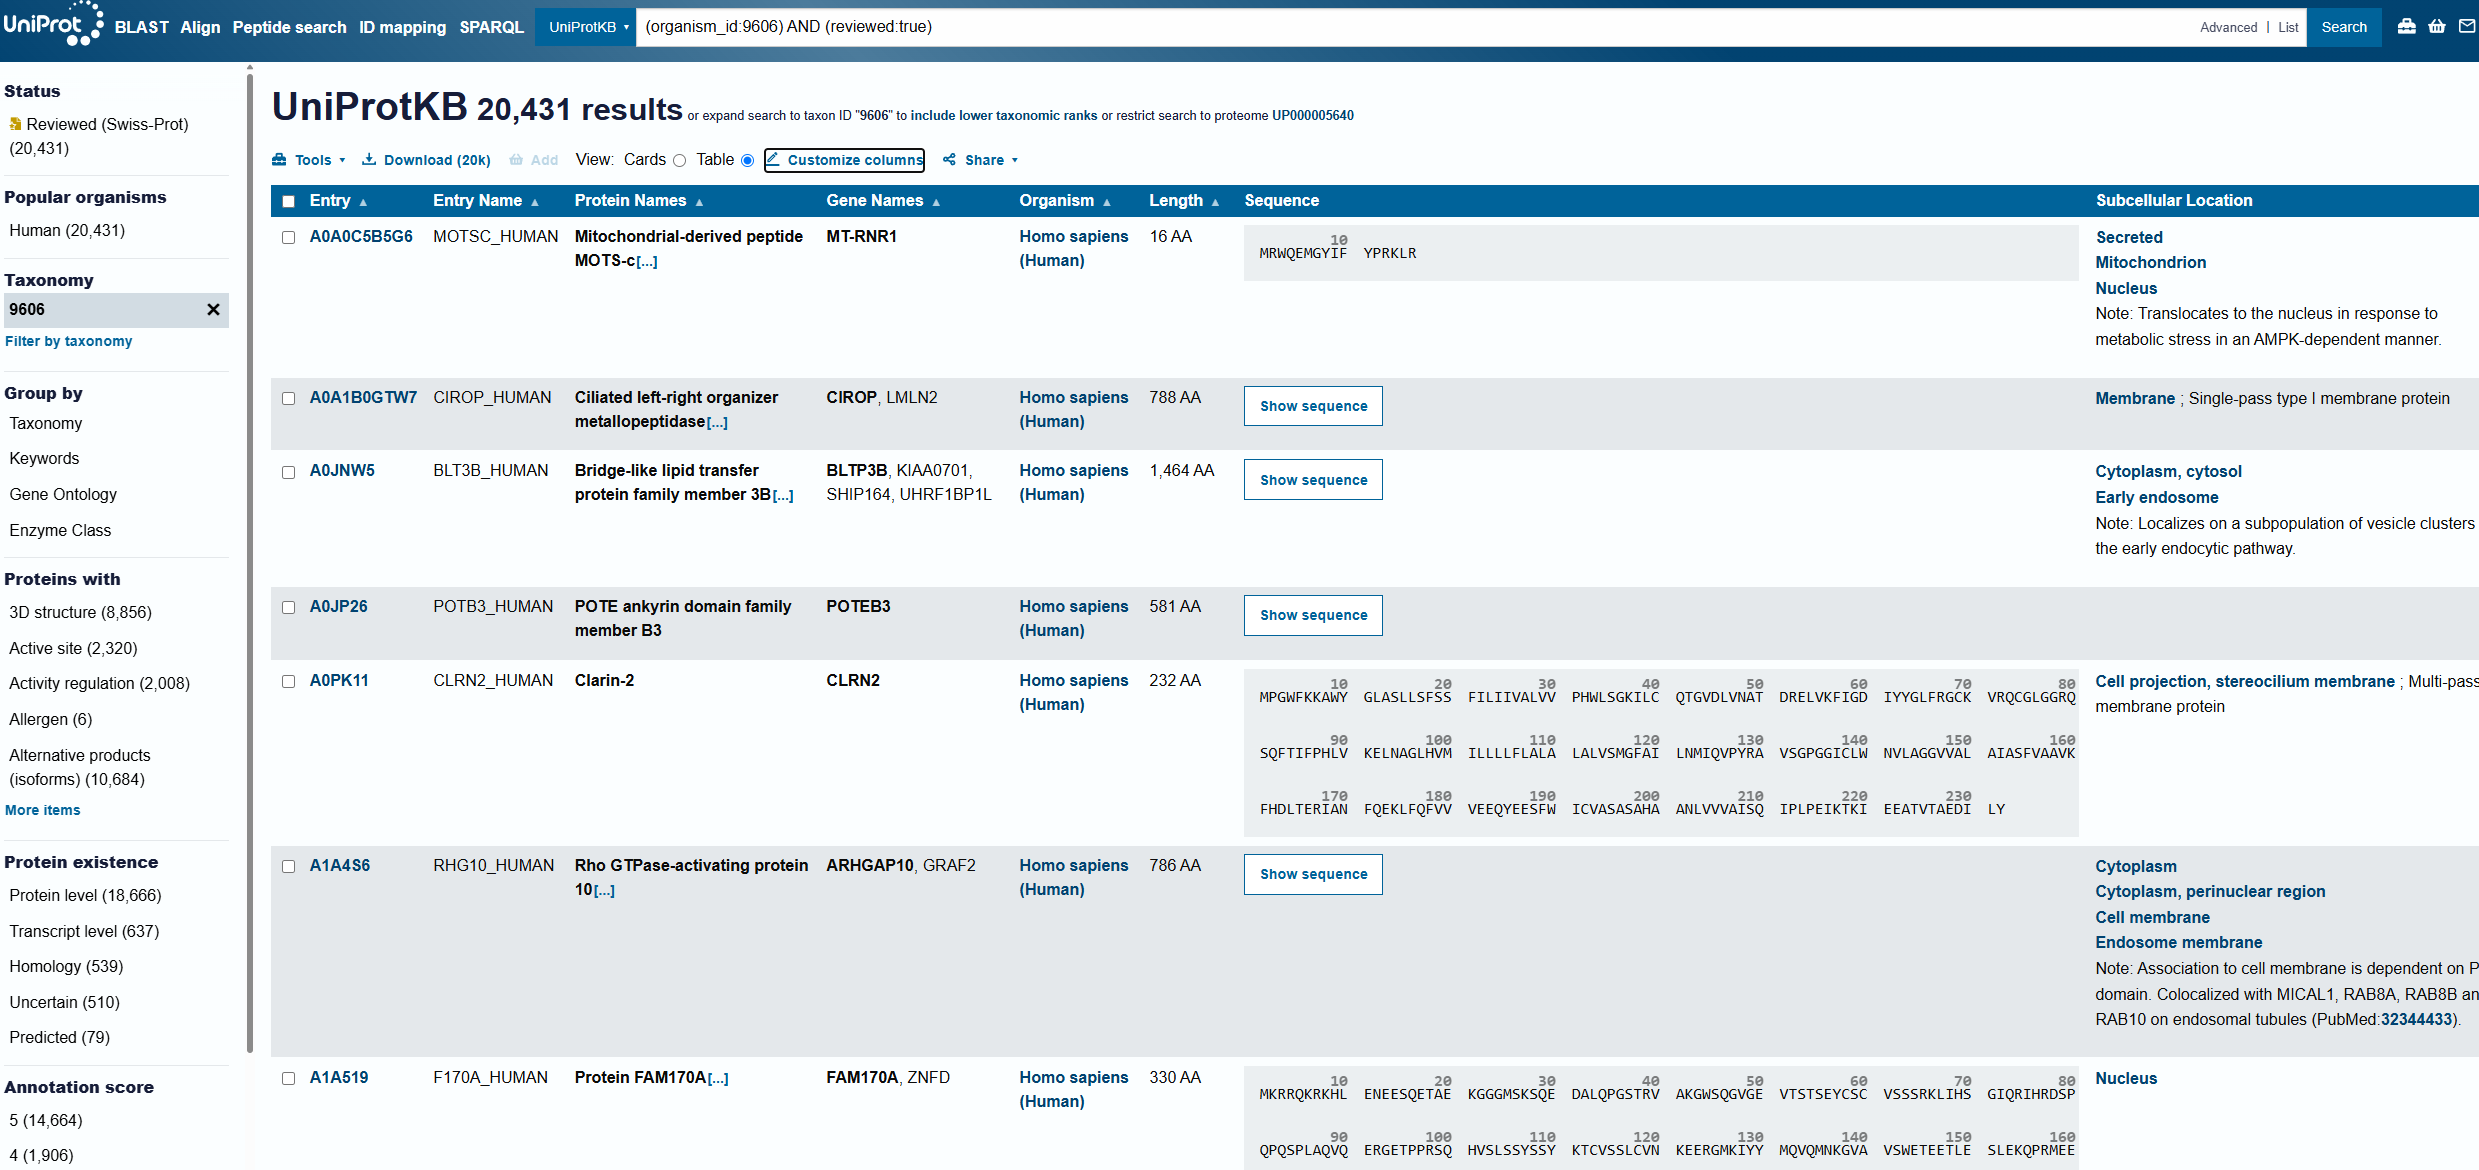

In [2]:
df_raw = pd.read_csv("../data/raw/uniprot_human_swissprot_raw.tsv", sep="\t")
df_raw.head(5)

,Entry,Entry Name,Protein names,Gene Names,Organism,Length,Sequence,Subcellular location [CC]
0,A0A087X1C5,CP2D7_HUMAN,Cytochrome P450 2D7 (EC 1.14.14.1),CYP2D7,Homo sapiens (Human),515,MGLEALVPLAMIVAIFLLLVDLMHRHQRWAARYPPGPLPLPGLGNL...,SUBCELLULAR LOCATION: Membrane {ECO:0000305}; ...
1,A0A096LP01,SIM26_HUMAN,Small integral membrane protein 26,SMIM26 LINC00493,Homo sapiens (Human),95,MYRNEFTAWYRRMSVVYGIGTWSVLGSLLYYSRTMAKSSVDQKDGS...,SUBCELLULAR LOCATION: Mitochondrion outer memb...
2,A0A0B4J2F0,PIOS1_HUMAN,Protein PIGBOS1 (PIGB opposite strand protein 1),PIGBOS1,Homo sapiens (Human),54,MFRRLTFAQLLFATVLGIAGGVYIFQPVFEQYAKDQKELKEKMQLV...,SUBCELLULAR LOCATION: Mitochondrion outer memb...
3,A0A0C5B5G6,MOTSC_HUMAN,Mitochondrial-derived peptide MOTS-c (Mitochon...,MT-RNR1,Homo sapiens (Human),16,MRWQEMGYIFYPRKLR,SUBCELLULAR LOCATION: Secreted {ECO:0000269|Pu...
4,A0A0K2S4Q6,CD3CH_HUMAN,Protein CD300H (CD300 antigen-like family memb...,CD300H,Homo sapiens (Human),201,MTQRAGAAMLPSALLLLCVPGCLTVSGPSTVMGAVGESLSVQCRYE...,SUBCELLULAR LOCATION: [Isoform 1]: Membrane {E...


In [3]:
df_raw.columns.tolist()

['Entry',
 'Entry Name',
 'Protein names',
 'Gene Names',
 'Organism',
 'Length',
 'Sequence',
 'Subcellular location [CC]']

Значение столбцов:
- Entry: Уникальный идентификатор записи
- Entry Name: Краткое имя записи
- Protein names: Названия белка
- Gene Names: Названия генов
- Organism: Организм
- Length: Длина последовательности
- Sequence: Аминокислотная последовательность
- Subcellular location [CC]: Текст аннотации локализации

In [4]:
print(f"Размер dataframe: {df_raw.shape}")

Размер dataframe: (17342, 8)


In [5]:
# Проверка info:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 17342 entries, 0 to 17341
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Entry                      17342 non-null  str  
 1   Entry Name                 17342 non-null  str  
 2   Protein names              17342 non-null  str  
 3   Gene Names                 17320 non-null  str  
 4   Organism                   17342 non-null  str  
 5   Length                     17342 non-null  int64
 6   Sequence                   17342 non-null  str  
 7   Subcellular location [CC]  17342 non-null  str  
dtypes: int64(1), str(7)
memory usage: 1.1 MB


Загружено 17 342 записи и 8 столбцов. Присутствуют идентификаторы белков, последовательности и текстовые аннотации локализации. Столбец Length имеет целочисленный тип.

## Проверка заполненности

In [6]:
# Проверка пропусков
df_raw.isna().sum()

Entry                         0
Entry Name                    0
Protein names                 0
Gene Names                   22
Organism                      0
Length                        0
Sequence                      0
Subcellular location [CC]     0
dtype: int64

Пропуски найдены только в столбце Gene Names

In [7]:
data = []
for col in ["Entry", "Sequence", "Subcellular location [CC]"]:
    nan = df_raw[col].isna().sum()
    none = len(df_raw[df_raw["Entry"] == ""])
    space = len(df_raw[df_raw["Entry"].str.isspace()])
    
    data.append([nan, none, space])
    
df_abs = pd.DataFrame(data=data, columns=["Пропуски", "Пустые строки",	"Строки только из пробелов"], index=["Entry", "Sequence", "Subcellular location"])
df_abs

,Пропуски,Пустые строки,Строки только из пробелов
Entry,0,0,0
Sequence,0,0,0
Subcellular location,0,0,0


Пропуски, пустые строки и строки, состоящие только из пробелов не обнаружены в df_raw на стадии первичного осмотра

## Проверка уникальных значений и повторов

In [8]:
# Проверка уникальных значений
df_raw.nunique()

Entry                        17342
Entry Name                   17342
Protein names                17342
Gene Names                   17284
Organism                         1
Length                        2111
Sequence                     17303
Subcellular location [CC]    12209
dtype: int64

In [9]:
# Проверка, что все записи относятся к одному организму
df_raw["Organism"].unique()

<StringArray>
['Homo sapiens (Human)']
Length: 1, dtype: str

Все записи относятся к человеку.

In [10]:
# Проверка дубликатов
df_raw.duplicated().sum()

np.int64(0)

Полные дубликаты строк отсутствуют.

In [11]:
print(f"Количество дубликатов в Sequence: {df_raw["Sequence"].duplicated().sum()}")

df_seq = df_raw.loc[df_raw["Sequence"].duplicated(keep=False), "Sequence"]
df_seq

Количество дубликатов в Sequence: 39


165      MSFLIDSSIMITSQILFFGFGWLFFMRQLFKDYEIRQYVVQVIFSV...
1790     MDMRVPAQLLGLLLLWLSGARCDIQMTQSPSSLSASVGDRVTITCQ...
1791     MDMRVPAQLLGLLLLWLSGARCDIQMTQSPSSLSASVGDRVTITCQ...
1792     MDMRVPAQLLGLLLLWLRGARCDIQMTQSPSSLSASVGDRVTITCR...
1794     MRLPAQLLGLLMLWVSGSSGDIVMTQSPLSLPVTPGEPASISCRSS...
                               ...                        
17053    MRLHLLLLILLLFSILLSPVRGGLGPAEGHCLNLFGVCRTDVCNIV...
17059    MNPSEMQRKAPPRRRRHRNRAPLTHKMNKMVTSEEQMKLPSTKKAE...
17060    MNPSEMQRKAPPRRRRHRNRAPLTHKMNKMVTSEEQMKLPSTKKAE...
17061    MNPSEMQRKAPPRRRRHRNRAPLTHKMNKMVTSEEQMKLPSTKKAE...
17065    MNPSEMQRKAPPRRRRHRNRAPLTHKMNKMVTSEEQMKLPSTKKAE...
Name: Sequence, Length: 68, dtype: str

In [12]:
print(f"Количество дубликатов Sequence c одинаковой локализацией: {df_raw[["Sequence", "Subcellular location [CC]"]].duplicated().sum()}")

Количество дубликатов Sequence c одинаковой локализацией: 30


## Проверка длины последовательностей

In [13]:
# Проверка describe
df_raw.describe()

,Length
count,17342.000000
mean,581.856533
std,635.439120
min,2.000000
25%,270.000000
50%,428.000000
75%,693.000000
max,34350.000000


In [14]:
seq_length = df_raw["Sequence"].str.len().to_frame(name="Length")

print(f"Проверка совпадений: {(seq_length["Length"] == df_raw["Length"]).sum() == df_raw.shape[0]}")

Проверка совпадений: True


Значение длины последовательностей корректа и совпадает с настоящей длиной

In [15]:
# Cамые короткие последовательности
print("5 cамых коротких последовательностей")
(df_raw[["Entry", "Protein names", "Length"]].sort_values(by=["Length"], ascending=True)).head(5)

5 cамых коротких последовательностей


,Entry,Protein names,Length
17047,P0DPR3,T cell receptor delta diversity 1,2
17046,P0DPI4,T cell receptor beta diversity 1,4
17042,P0DOY5,Immunoglobulin heavy diversity 1-1,5
16829,A0A0A0MT89,Immunoglobulin kappa joining 1,12
17306,A0A0J9YXA8,T cell receptor beta joining 1-1,15


Иммунобелки имеют самые короткие последовательности

In [16]:
# Cамые длинные последовательности
print("5 cамых длинных коротких последовательностей")
(df_raw[["Entry", "Protein names", "Length"]].sort_values(by=["Length"], ascending=False)).head(5)

5 cамых длинных коротких последовательностей


,Entry,Protein names,Length
9209,Q8WZ42,Titin (EC 2.7.11.1) (Connectin) (Rhabdomyosarc...,34350
9171,Q8WXI7,Mucin-16 (MUC-16) (Ovarian cancer-related tumo...,14507
11158,Q9H195,Mucin-3B (MUC-3B) (Intestinal mucin-3B),13477
8671,Q8NF91,Nesprin-1 (Enaptin) (KASH domain-containing pr...,8797
2920,P20929,Nebulin,8525


Титин — это гигантский белок, самый крупный из известных белков в организме млекопитающих.

## Проверка символов последовательностей

| Аминокислота          | Трёхбуквенный код | Однобуквенный код |
| --------------------- | ----------------- | ----------------- |
| Аланин                | Ala               | A                 |
| Аргинин               | Arg               | R                 |
| Аспарагин             | Asn               | N                 |
| Аспарагиновая кислота | Asp               | D                 |
| Цистеин               | Cys               | C                 |
| Глутамин              | Gln               | Q                 |
| Глутаминовая кислота  | Glu               | E                 |
| Глицин                | Gly               | G                 |
| Гистидин              | His               | H                 |
| Изолейцин             | Ile               | I                 |
| Лейцин                | Leu               | L                 |
| Лизин                 | Lys               | K                 |
| Метионин              | Met               | M                 |
| Фенилаланин           | Phe               | F                 |
| Пролин                | Pro               | P                 |
| Серин                 | Ser               | S                 |
| Треонин               | Thr               | T                 |
| Триптофан             | Trp               | W                 |
| Тирозин               | Tyr               | Y                 |
| Валин                 | Val               | V                 |

In [17]:
# Проверка, что все все символы заглавные
print(f"Проверка, что все символы заглавные во всех строках: {df_raw["Sequence"].str.isupper().sum() == df_raw.shape[0]}")

Проверка, что все символы заглавные во всех строках: True


In [18]:
print(f"Количество корректных последовательностей из 20 аминокислот из {df_raw.shape[0]} строк: {df_raw["Sequence"].str.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY]+", na=False).sum()}")

print(f"Количество корректных последовательностей из 21 аминокислоты (включая селеноцистеин U) из {df_raw.shape[0]} строк: {df_raw["Sequence"].str.fullmatch(r"[ACDEFGHIKLMNPQRSTVWYU]+", na=False).sum()}")

Количество корректных последовательностей из 20 аминокислот из 17342 строк: 17319
Количество корректных последовательностей из 21 аминокислоты (включая селеноцистеин U) из 17342 строк: 17342


In [19]:
mask = df_raw["Sequence"].str.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY]+", na=False)

print(f"Список индексов последовательностей с селеноцистеином: {df_raw.loc[~mask, "Sequence"].index.tolist()}")
df_raw.loc[~mask, "Sequence"]

Список индексов последовательностей с селеноцистеином: [971, 2077, 2790, 2993, 3632, 4088, 4092, 4407, 4701, 6279, 7823, 9134, 9337, 10352, 10501, 10720, 11006, 11680, 12317, 12318, 13575, 14005, 15737]


971      MVAMAAGPSGCLVPAFGLRLLLATVLQAVSAFGAEFSSEACRELGF...
2077     MCAARLAAAAAAAQSVYAFSARPLAGGEPVSLGSLRGKVLLIENVA...
2790     MAFIAKSFYDLSAISLDGEKVDFNTFRGRAVLIENVASLUGTTTRD...
2993     MARLLQASCLLSLLLAGFVSQSRGQEKSKMDCHGGISGTIYEYGAL...
3632     MSLGRLCRLLKPALLCGALAAPGLAGTMCASRDDWRCARSMHEFSA...
4088     MGLPQPGLWLKRLWVLLEVAVHVVVGKVLLILFPDRVKRNILAMGE...
4092     MWRSLGLALALCLLPSGGTESQDQSSLCKQPPAWSIRDQDPMLNSN...
4407     MPRQATSRLVVGEGEGSQGASGPAATMLRSLLLHSLRLCAQTASCL...
4701     MRLLLLLLVAASAMVRSEASANLGGVPSKRLKMQYATGPLLKFQIC...
6279     MGCAEGKAVAAAAPTELQTKGKNGDGRRRSAKDHHPGKTLPENPAG...
7823     MERSPPQSPGPGKAGDAPNRRSGHVRGARVLSPPGRRARLSSPGPS...
9134     MSLLLPPLALLLLLAALVAPATAATAYRPDWNRLSGLTRARVETCG...
9337     MGILSVDLLITLQILPVFFSNCLFLALYDSVILLKHVVLLLSRSKS...
10352    MAEASATGACGEAMAAAEGSSGPAGLTLGRSFSNYRPFEPQALGLS...
10501    MERQEESLSARPALETEGLRFLHTTVGSLLATYGWYIVFSCILLYV...
10720    MAVYRAALGASLAAARLLPLGRCSPSPAPRSTLSGAAMEPAPRWLA...
11006    MAGYEYVSPEQLAGFDKYKYSAVDTNPLSLYVMHPFWNTIVKVFPT.

Символы последовательностей почти корректны, некоторые состоят из 21 аминокислот. В последовательностях есть буква U — это селеноцистеин (Sec) аминокислота, которая встречается в UniProt, но не входит в набор из 20 канонических остатков. 

## Просмотр формата аннотаций локализации

In [20]:
# Пример и проверка источника будущей целевой метки
pd.set_option("display.max_colwidth", None)
df_raw["Subcellular location [CC]"].head(5)

0                                                                                                                                 SUBCELLULAR LOCATION: Membrane {ECO:0000305}; Multi-pass membrane protein {ECO:0000255}. Cytoplasm {ECO:0000305|PubMed:15051713}. Mitochondrion {ECO:0000269|PubMed:18838503}.
1                                                                                                                                                     SUBCELLULAR LOCATION: Mitochondrion outer membrane {ECO:0000269|PubMed:33386847, ECO:0000269|PubMed:37009826}; Single-pass membrane protein {ECO:0000255}.
2                                                                                                                                                                                  SUBCELLULAR LOCATION: Mitochondrion outer membrane {ECO:0000269|PubMed:31653868}; Single-pass membrane protein {ECO:0000255}.
3    SUBCELLULAR LOCATION: Secreted {ECO:0000269|PubMed:25738459}. Mitochondrion {ECO

Столбец локализации содержит структурированные текстовые аннотации, а не готовые метки классов. Для получения целевой переменной потребуется согласовать правила разбора текста, обработки нескольких локализаций и изоформ.